# Student Segmentation: Clustering the Campus Placement Dataset

## Project Overview

This mini project applies **unsupervised learning** to the *Factors Affecting Campus Placement* dataset (Kaggle). The dataset describes 215 students through their academic percentages at different education levels, their school boards and study streams, work experience, and MBA specialisation.

Three clustering algorithms are implemented and compared:

- **K-Means**
- **Hierarchical (Agglomerative) Clustering**
- **DBSCAN**

## Objective

The goal is to discover natural groups of students based on their academic and background profiles, **without using the placement outcome**. The project aims to:

1. Prepare the data for distance-based clustering (cleaning, encoding, scaling).
2. Apply and tune K-Means, Hierarchical Clustering, and DBSCAN.
3. Evaluate the clusters with the **Silhouette Score** and cluster profiling.
4. Compare the algorithms and identify the most suitable one for this dataset.

## Notebook Structure

1. Setup and Libraries
2. Dataset Overview
3. Data Quality Checks
4. Data Preprocessing
5. K-Means Clustering
6. Hierarchical Clustering
7. DBSCAN
8. Cluster Profiling
9. Algorithm Comparison
10. Key Insights
11. Final Conclusion

## 1. Setup and Libraries

The following libraries are used in this project:

- **pandas / numpy** for data handling and numerical operations.
- **matplotlib / seaborn** for visualizations.
- **kagglehub / os** for downloading and locating the dataset.
- **scikit-learn** for preprocessing (`StandardScaler`), the three clustering algorithms (`KMeans`, `DBSCAN`, `AgglomerativeClustering`), and evaluation (`silhouette_score`).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

## 2. Dataset Overview

### 2.1 Loading the Data

The dataset is downloaded directly from Kaggle with `kagglehub`, and the CSV file `Placement_Data_Full_Class.csv` is loaded into a pandas DataFrame. The first five rows give a quick view of the available columns.

In [ ]:
path = kagglehub.dataset_download("benroshan/factors-affecting-campus-placement")
print("Path to dataset files:", path)

csv_path = os.path.join(path, "Placement_Data_Full_Class.csv")

df = pd.read_csv(csv_path)
df.head()


Using Colab cache for faster access to the 'factors-affecting-campus-placement' dataset.
Path to dataset files: /kaggle/input/factors-affecting-campus-placement


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


**Observation:** Each row represents one student. The columns include:

- **Academic percentages:** `ssc_p` (secondary school), `hsc_p` (higher secondary), `degree_p` (undergraduate degree), `etest_p` (employability test), and `mba_p` (MBA).
- **Background information:** `gender`, `ssc_b` and `hsc_b` (school boards), `hsc_s` (higher secondary stream), `degree_t` (degree type), `workex` (work experience), and `specialisation` (MBA specialisation).
- **Outcome information:** `status` (Placed / Not Placed) and `salary`.
- **Identifier:** `sl_no` (serial number).

### 2.2 Data Structure and Data Types

`df.info()` shows the number of rows, column data types, and non-null counts. This helps us decide which columns need encoding, scaling, or removal.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 non-null    object 
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), object(8)
memory usage: 25.3+ KB


**Observation:**

- The dataset has **215 rows** and **15 columns**.
- There are **6 float columns**, **1 integer column** (`sl_no`), and **8 object (categorical) columns**.
- Only `salary` has missing values (148 non-null out of 215).
- The mix of numerical and categorical columns means we will need **both scaling and encoding** before clustering.

## 3. Data Quality Checks

Clustering algorithms rely on distances between data points, so missing values and duplicate rows can distort the results. This section checks both.

### 3.1 Missing Values

The percentage of missing values is calculated for every column.

In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
sl_no,0.000000
gender,0.000000
ssc_p,0.000000
ssc_b,0.000000
hsc_p,0.000000
hsc_b,0.000000
hsc_s,0.000000
degree_p,0.000000
degree_t,0.000000
workex,0.000000


**Observation:** `salary` is the only column with missing values (**31.16%**). All other columns are complete. Because `salary` is an outcome variable and not a student characteristic, it is removed in the preprocessing step instead of being imputed.

### 3.2 Duplicate Records

A helper function counts duplicate rows and removes them if any are found. Duplicates would give some students extra weight when the clusters are formed.

In [ ]:
def check_duplicates(df):
  duplicates = df.duplicated().sum()
  print(f"Number of Duplicate Samples: {duplicates}")
  if duplicates > 0:
    print("Dropping Duplicates...")
    df.drop_duplicates(inplace=True)
    print("Duplicates Dropped.")
  else:
    print("No Duplicate Samples Found.")

check_duplicates(df)

Number of Duplicate Samples: 0
No Duplicate Samples Found.


**Observation:** No duplicate records were found, so all 215 students are kept.

## 4. Data Preprocessing

### 4.1 Removing Unnecessary Columns

Three columns are dropped:

- `sl_no` is only a row identifier and carries no information about the student.
- `status` and `salary` are **placement outcomes**. Removing them keeps the analysis truly unsupervised: the clusters are formed only from student characteristics. (`salary` also has 31% missing values.)

In [ ]:
# Drop unnecessary columns
df = df.drop(['salary', 'sl_no', 'status'], axis=1)
df.head()

,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p
0,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80
1,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28
2,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80
3,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43
4,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50


**Observation:** The DataFrame now contains **12 columns**: 5 numerical academic scores and 7 categorical background features.

### 4.2 Feature Scaling and Encoding

Two transformations are applied:

1. **Standardization (`StandardScaler`)** on the numerical columns. Each feature is transformed to have a mean of 0 and a standard deviation of 1. This is important because K-Means, Hierarchical Clustering, and DBSCAN are all distance-based, and features on larger scales would otherwise dominate the distance calculation.
2. **One-hot encoding (`pd.get_dummies` with `drop_first=True`)** on the categorical columns. Each category becomes a binary column, and the first category of each feature is dropped to avoid redundant columns.

In [ ]:
numrical_features = df.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df.select_dtypes(include=['object']).columns


scaler = StandardScaler()
df[numrical_features] = scaler.fit_transform(df[numrical_features])

df = pd.get_dummies(df, columns=categorical_features, drop_first=True)

df.head()

,ssc_p,hsc_p,degree_p,etest_p,mba_p,gender_M,ssc_b_Others,hsc_b_Others,hsc_s_Commerce,hsc_s_Science,degree_t_Others,degree_t_Sci&Tech,workex_Yes,specialisation_Mkt&HR
0,-0.028087,2.268812,-1.140102,-1.291091,-0.597647,True,True,True,True,False,False,True,False,True
1,1.113369,1.103448,1.513267,1.087157,0.687620,True,False,True,False,True,False,True,True,False
2,-0.213238,0.153313,-0.322843,0.218908,-0.769474,True,False,False,False,False,False,False,False,False
3,-1.046417,-1.318339,-1.957362,-0.460592,-0.489396,True,False,False,False,True,False,True,False,True
4,1.712332,0.668391,0.943909,1.864806,-1.164676,True,False,False,True,False,False,False,False,False


**Observation:**

- The five academic scores are now standardized (values around 0, roughly between -2.5 and 3.5).
- The categorical features have been converted into binary (True/False) columns, giving **14 features** in total.
- Note: the binary columns take values 0/1 and are not standardized, so the numerical and binary features are on slightly different scales.

### 4.3 Defining the Feature Matrix

A copy of the processed DataFrame is stored as `X`. This matrix is used as the input for all clustering models, while cluster labels are later added to `df` only. This keeps the feature matrix clean and unchanged.

In [ ]:
# Keep original clustering features separate
X = df.copy()

## 5. K-Means Clustering

### How K-Means Works

K-Means divides the data into **k** groups:

1. It places *k* cluster centres (centroids).
2. Each point is assigned to its nearest centroid.
3. Each centroid is moved to the mean of the points assigned to it.
4. Steps 2-3 repeat until the assignments stop changing.

The algorithm tries to make the points inside each cluster as close as possible to their centroid.

### Why K-Means Is Used

K-Means is simple, fast, and easy to interpret. It is a standard baseline for clustering numerical, scaled data such as student scores.

### Parameters Used

- `n_clusters=2`: the data is split into two groups. This choice is later checked with the Silhouette Score (Section 5.4).
- `random_state=42`: fixes the random initialization of the centroids so the results are reproducible.

### 5.1 Fitting the K-Means Model

The model is trained on `X`, and the resulting labels are stored in a new `Cluster` column of `df`.

In [ ]:
# K-Means
kmeans = KMeans(n_clusters=2, random_state=42)
labels_kmeans = kmeans.fit_predict(X)

df["Cluster"] = labels_kmeans

df.head()

,ssc_p,hsc_p,degree_p,etest_p,mba_p,gender_M,ssc_b_Others,hsc_b_Others,hsc_s_Commerce,hsc_s_Science,degree_t_Others,degree_t_Sci&Tech,workex_Yes,specialisation_Mkt&HR,Cluster
0,-0.028087,2.268812,-1.140102,-1.291091,-0.597647,True,True,True,True,False,False,True,False,True,1
1,1.113369,1.103448,1.513267,1.087157,0.687620,True,False,True,False,True,False,True,True,False,0
2,-0.213238,0.153313,-0.322843,0.218908,-0.769474,True,False,False,False,False,False,False,False,False,1
3,-1.046417,-1.318339,-1.957362,-0.460592,-0.489396,True,False,False,False,True,False,True,False,True,1
4,1.712332,0.668391,0.943909,1.864806,-1.164676,True,False,False,True,False,False,False,False,False,0


### 5.2 Cluster Sizes

Checking the number of students in each cluster shows whether the split is balanced.

In [ ]:
print("K-Means Cluster Sizes:")
print(df["Cluster"].value_counts().sort_index())

K-Means Cluster Sizes:
Cluster
0     98
1    117
Name: count, dtype: int64


**Observation:** K-Means produced two fairly balanced clusters: **98 students in Cluster 0** and **117 students in Cluster 1**. Neither cluster is dominated by a small group of outliers.

### 5.3 Visualizing the K-Means Clusters

The scatter plot shows students by their standardized secondary school percentage (`ssc_p`) and degree percentage (`degree_p`), coloured by K-Means cluster. Only 2 of the 14 features can be shown, so the plot is a partial view of the clustering.

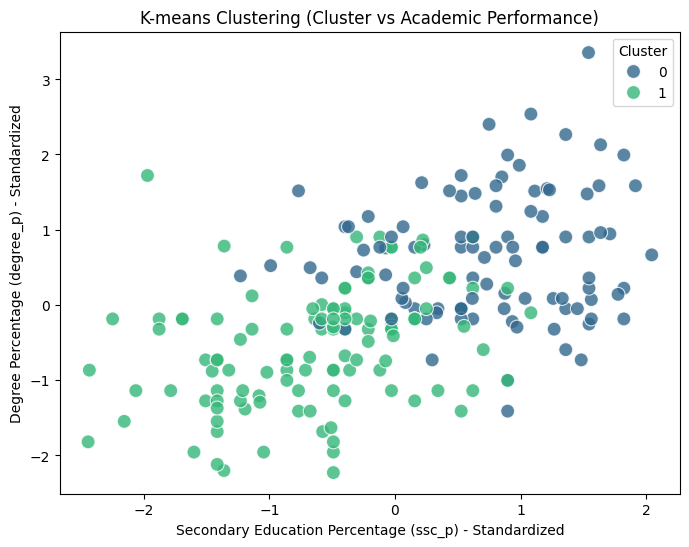

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='ssc_p', y='degree_p', hue='Cluster', palette='viridis', s=100, alpha=0.8)
plt.title('K-means Clustering (Cluster vs Academic Performance)')
plt.xlabel('Secondary Education Percentage (ssc_p) - Standardized')
plt.ylabel('Degree Percentage (degree_p) - Standardized')
plt.legend(title='Cluster')
plt.show()

**Interpretation:**

- **What it shows:** each point is a student, placed by their `ssc_p` and `degree_p` scores and coloured by cluster.
- **Pattern:** Cluster 0 is mainly located in the upper-right area (higher secondary and degree scores), while Cluster 1 is mainly in the lower-left area (lower scores).
- **Overlap:** the two clusters overlap in the centre of the plot (around 0 on both axes). This is expected because the model also uses the other academic scores and the categorical features, which are not shown here.
- **Conclusion:** K-Means mainly separates students by **overall academic performance**, but the boundary between the groups is not sharp.

### 5.4 Choosing the Number of Clusters (Silhouette Analysis)

To check whether `k=2` is a good choice, K-Means is run for **k = 2 to 10** and the **Silhouette Score** is calculated for each value.

**Silhouette Score:** for each point, it compares the average distance to points in its own cluster with the average distance to points in the nearest other cluster. The score ranges from **-1 to 1**:

- Close to **1**: points are well matched to their own cluster and clearly separated from others.
- Around **0**: clusters overlap.
- Negative: points may be in the wrong cluster.

A higher average score indicates better-defined clusters.

In [ ]:
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    print(f"K={k}: Silhouette={score:.4f}")

K=2: Silhouette=0.2015
K=3: Silhouette=0.1462
K=4: Silhouette=0.1215
K=5: Silhouette=0.1203
K=6: Silhouette=0.1177
K=7: Silhouette=0.1062
K=8: Silhouette=0.1114
K=9: Silhouette=0.0915
K=10: Silhouette=0.1039


**Interpretation:**

- The highest Silhouette Score is at **k = 2 (0.2015)**, which supports the choice of two clusters.
- The score generally decreases as *k* increases (down to 0.0915 at k = 9), so adding more clusters does not create better-separated groups.
- However, a score of about 0.20 is **relatively low**. This indicates that the clusters exist but **overlap considerably**, which matches the overlap seen in the scatter plot.

### 5.5 K-Means: Strengths and Limitations

| Strengths | Limitations |
|---|---|
| Simple, fast, and easy to interpret | The number of clusters must be chosen in advance |
| Produced balanced clusters (98 / 117) | Assumes roughly round, similar-sized clusters |
| Best Silhouette Score among the K-Means options at k = 2 | Sensitive to feature scaling and to outliers |
| Every student is assigned to a cluster | Silhouette Score of 0.2015 shows weak separation |

## 6. Hierarchical Clustering (Agglomerative)

### How It Works

Agglomerative clustering is a **bottom-up** method:

1. Each student starts as their own cluster.
2. At each step, the two closest clusters are merged.
3. Merging continues until the requested number of clusters remains.

The **linkage** method defines how the distance between two clusters is measured:

- **Ward:** merges the pair of clusters that causes the smallest increase in within-cluster variance (similar goal to K-Means).
- **Complete:** uses the largest distance between points of the two clusters.
- **Average:** uses the average distance between all pairs of points.
- **Single:** uses the smallest distance between points of the two clusters.

### Why It Is Used

Hierarchical clustering does not rely on random initialization, and it offers a different way to build clusters. This makes it a useful comparison with K-Means.

### Parameters Used

- `n_clusters=2`: the same number of clusters as K-Means, so the two methods can be compared directly.
- `linkage="ward"`: the main model uses Ward linkage. Other linkage methods are tested in Section 6.2.

### 6.1 Fitting the Ward Model

The labels are stored in a new `HC_Cluster` column of `df`.

In [ ]:
hc = AgglomerativeClustering(n_clusters=2, linkage="ward")

labels_hc = hc.fit_predict(X)

df["HC_Cluster"] = labels_hc

df.head()

,ssc_p,hsc_p,degree_p,etest_p,mba_p,gender_M,ssc_b_Others,hsc_b_Others,hsc_s_Commerce,hsc_s_Science,degree_t_Others,degree_t_Sci&Tech,workex_Yes,specialisation_Mkt&HR,Cluster,HC_Cluster
0,-0.028087,2.268812,-1.140102,-1.291091,-0.597647,True,True,True,True,False,False,True,False,True,1,0
1,1.113369,1.103448,1.513267,1.087157,0.687620,True,False,True,False,True,False,True,True,False,0,0
2,-0.213238,0.153313,-0.322843,0.218908,-0.769474,True,False,False,False,False,False,False,False,False,1,1
3,-1.046417,-1.318339,-1.957362,-0.460592,-0.489396,True,False,False,False,True,False,True,False,True,1,1
4,1.712332,0.668391,0.943909,1.864806,-1.164676,True,False,False,True,False,False,False,False,False,0,0


**Observation:** The new `HC_Cluster` column is added next to the K-Means `Cluster` column. The cluster numbers (0 and 1) are arbitrary in each method, so they should be compared through cluster sizes and profiles rather than by label number.

### 6.2 Comparing Linkage Methods

To understand the effect of the linkage choice, all four linkage methods are tested with two clusters, first by Silhouette Score and then by cluster sizes.

In [ ]:
for linkage in ["ward", "complete", "average", "single"]:

    model = AgglomerativeClustering(n_clusters=2, linkage=linkage)

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    print(f"{linkage}: {score:.4f}")

ward: 0.1646
complete: 0.1695
average: 0.2800
single: 0.2800


**Observation:** Average and single linkage give the highest Silhouette Scores (**0.2800**), followed by complete (0.1695) and Ward (0.1646). The cluster sizes below are needed to understand whether these higher scores are meaningful.

In [ ]:
for linkage in ["ward", "complete", "average", "single"]:

    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=linkage
    )

    labels = model.fit_predict(X)

    print(f"\n{linkage.upper()}")
    print(pd.Series(labels).value_counts())


WARD
0    134
1     81
Name: count, dtype: int64

COMPLETE
0    171
1     44
Name: count, dtype: int64

AVERAGE
0    214
1      1
Name: count, dtype: int64

SINGLE
0    214
1      1
Name: count, dtype: int64


**Interpretation:**

| Linkage | Cluster sizes | Silhouette |
|---|---|---|
| Ward | 134 / 81 | 0.1646 |
| Complete | 171 / 44 | 0.1695 |
| Average | 214 / 1 | 0.2800 |
| Single | 214 / 1 | 0.2800 |

- Average and single linkage separate **only one student** from the rest. Their higher Silhouette Score comes from isolating a single outlier, **not** from finding a useful grouping.
- Complete linkage produces an unbalanced split (171 / 44).
- **Ward linkage** gives the most balanced and meaningful split (134 / 81). This supports keeping Ward as the final hierarchical model, even though its Silhouette Score is lower.
- This is a good example of why the Silhouette Score should always be checked together with cluster sizes.

### 6.3 Visualizing the Hierarchical Clusters

The same two features (`ssc_p` and `degree_p`) are used so the result can be compared directly with the K-Means plot.

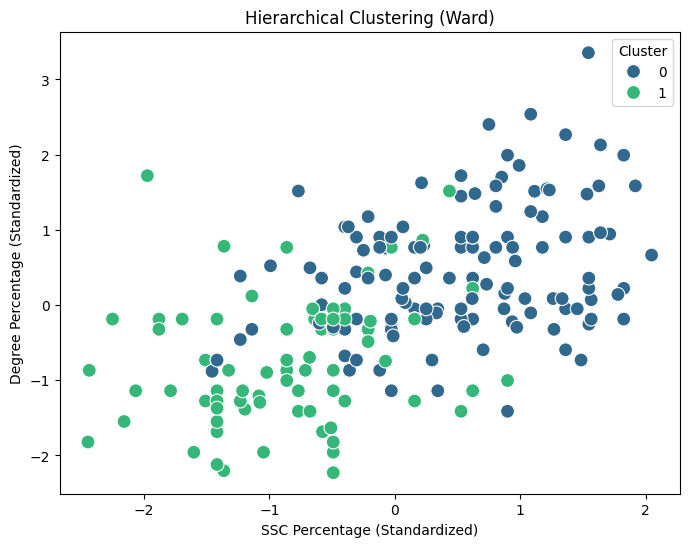

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="ssc_p",
    y="degree_p",
    hue="HC_Cluster",
    palette="viridis",
    s=100
)

plt.title("Hierarchical Clustering (Ward)")
plt.xlabel("SSC Percentage (Standardized)")
plt.ylabel("Degree Percentage (Standardized)")
plt.legend(title="Cluster")
plt.show()

**Interpretation:**

- **What it shows:** students coloured by their Ward hierarchical cluster.
- **Pattern:** Cluster 0 (134 students) covers the upper-right and central areas, while Cluster 1 (81 students) is concentrated in the lower-left area with lower secondary and degree scores.
- **Comparison with K-Means:** the overall structure is similar (higher-scoring vs. lower-scoring students), but Ward assigns more of the middle-range students to Cluster 0, so its "lower" group is smaller.
- **Conclusion:** both methods find a similar academic-performance pattern, with some overlap in the middle of the plot.

### 6.4 Silhouette Scores of the Final K-Means and Hierarchical Models

The Silhouette Score of the two final models is calculated on the feature columns only (the `Cluster` and `HC_Cluster` label columns are excluded).

*Note:* this cell is placed before the DBSCAN section because DBSCAN later adds another label column (`DBSCAN_Demo`) to `df`. Running this cell first keeps the feature set identical to `X`.

In [ ]:
features = df.drop(columns=['Cluster', 'HC_Cluster'], errors='ignore')

sil_kmeans = silhouette_score(features, df['Cluster'])
sil_hc = silhouette_score(features, df['HC_Cluster'])

print(f"Silhouette Score for K-means: {sil_kmeans:.4f}")
print(f"Silhouette Score for Hierarchical Clustering (HC): {sil_hc:.4f}")

Silhouette Score for K-means: 0.2015
Silhouette Score for Hierarchical Clustering (HC): 0.1646


**Interpretation:**

- **K-Means: 0.2015**
- **Hierarchical (Ward): 0.1646**

K-Means achieves a higher Silhouette Score, which means its two clusters are slightly more compact and better separated than the Ward clusters. Both scores are low, so the separation is weak for both methods.

### 6.5 Hierarchical Clustering: Strengths and Limitations

| Strengths | Limitations |
|---|---|
| No random initialization, so results are deterministic | Slower than K-Means on large datasets |
| Linkage choice gives flexibility in cluster shape | Results depend strongly on the linkage method |
| Ward linkage produced a meaningful split (134 / 81) | Average and single linkage isolated only one outlier |
| Can reveal nested group structure | Ward Silhouette Score (0.1646) is lower than K-Means |

## 7. DBSCAN (Density-Based Clustering)

### How DBSCAN Works

DBSCAN groups together points that are in **dense regions**:

- A point is a **core point** if at least `min_samples` points lie within a distance of `eps` from it.
- Clusters are formed by connecting core points that are close to each other, together with their neighbouring points.
- Points that do not belong to any dense region are labelled as **noise (-1)**.

### Why DBSCAN Is Used

Unlike K-Means and Hierarchical Clustering, DBSCAN does **not** need the number of clusters in advance, it can find clusters of any shape, and it can detect outliers. This makes it a useful test of whether the data contains clear dense groups.

### Parameters Tuned

- `eps`: the neighbourhood radius. Tested values: 0.5, 1, 1.5, 2, 2.5, 3, 4.
- `min_samples`: the minimum number of neighbours needed to form a dense region. Tested values: 3, 5, 10.

### 7.1 Parameter Grid Search

All 21 combinations of `eps` and `min_samples` are tested, and the number of clusters and noise points is recorded for each.

In [ ]:
for eps in [0.5, 1, 1.5, 2, 2.5, 3, 4]:
    for min_samples in [3, 5, 10]:

        dbscan = DBSCAN(eps=eps, min_samples=min_samples)

        labels = dbscan.fit_predict(X)

        n_clusters = len(set(labels) - {-1})
        n_noise = (labels == -1).sum()

        print(
            f"eps={eps}, "
            f"min_samples={min_samples}, "
            f"clusters={n_clusters}, "
            f"noise={n_noise}"
        )

eps=0.5, min_samples=3, clusters=0, noise=215
eps=0.5, min_samples=5, clusters=0, noise=215
eps=0.5, min_samples=10, clusters=0, noise=215
eps=1, min_samples=3, clusters=0, noise=215
eps=1, min_samples=5, clusters=0, noise=215
eps=1, min_samples=10, clusters=0, noise=215
eps=1.5, min_samples=3, clusters=12, noise=140
eps=1.5, min_samples=5, clusters=3, noise=182
eps=1.5, min_samples=10, clusters=0, noise=215
eps=2, min_samples=3, clusters=1, noise=31
eps=2, min_samples=5, clusters=1, noise=39
eps=2, min_samples=10, clusters=1, noise=89
eps=2.5, min_samples=3, clusters=1, noise=2
eps=2.5, min_samples=5, clusters=1, noise=2
eps=2.5, min_samples=10, clusters=1, noise=3
eps=3, min_samples=3, clusters=1, noise=0
eps=3, min_samples=5, clusters=1, noise=0
eps=3, min_samples=10, clusters=1, noise=0
eps=4, min_samples=3, clusters=1, noise=0
eps=4, min_samples=5, clusters=1, noise=0
eps=4, min_samples=10, clusters=1, noise=0


**Interpretation:**

- **eps = 0.5 and 1:** every student is labelled as noise (0 clusters). The neighbourhood is too small for the 14-dimensional feature space.
- **eps = 1.5:** this is the only value that creates more than one cluster (12 clusters with `min_samples=3`, 3 clusters with `min_samples=5`), but most students are still noise (140 and 182 points).
- **eps >= 2:** almost all students fall into **one single cluster**, with the number of noise points decreasing to 0 from eps = 3.
- **Conclusion:** there is no `eps` value that produces several clusters with low noise. This suggests the data does **not** contain clearly separated dense regions; the students form one continuous cloud of points.

### 7.2 Grid Search with Silhouette Scores

The same grid is repeated, but this time the Silhouette Score is also calculated. Noise points are excluded from the score, and the score is only calculated when there are at least two clusters.

In [ ]:
dbscan_results = []

for eps in [0.5, 1, 1.5, 2, 2.5, 3, 4]:
    for min_samples in [3, 5, 10]:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X)

        # Exclude noise when evaluating clusters
        mask = labels != -1

        n_clusters = len(set(labels) - {-1})
        n_noise = (~mask).sum()

        if 2 <= n_clusters < mask.sum():
            score = silhouette_score(
                X.loc[mask],
                labels[mask]
            )
        else:
            score = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise": n_noise,
            "Silhouette": score
        })

dbscan_results = pd.DataFrame(dbscan_results)

dbscan_results.sort_values(
    "Silhouette",
    ascending=False
).head(10)

,eps,min_samples,Clusters,Noise,Silhouette
7,1.5,5,3,182,0.242907
6,1.5,3,12,140,0.216528
0,0.5,3,0,215,NaN
1,0.5,5,0,215,NaN
2,0.5,10,0,215,NaN
3,1.0,3,0,215,NaN
4,1.0,5,0,215,NaN
5,1.0,10,0,215,NaN
8,1.5,10,0,215,NaN
9,2.0,3,1,31,NaN


**Interpretation:**

- Only two configurations produce a valid Silhouette Score:
  - `eps=1.5, min_samples=5`: 3 clusters, **182 noise points**, Silhouette = **0.2429**
  - `eps=1.5, min_samples=3`: 12 clusters, **140 noise points**, Silhouette = **0.2165**
- These scores look higher than K-Means, but they are calculated **only on the non-noise points** (33 and 75 students respectively). Most of the dataset is ignored, so these scores are **not directly comparable** with the K-Means and Hierarchical scores.

### 7.3 Selecting a Final DBSCAN Configuration

A configuration is accepted only if it meets all three conditions:

- at least **2 clusters**,
- **less than 50%** of the points labelled as noise,
- a valid Silhouette Score.

These rules prevent selecting a model that ignores most of the data.

In [ ]:
# Select a valid configuration with at least
# two clusters and reasonable noise coverage

valid_results = dbscan_results[
    (dbscan_results["Clusters"] >= 2) &
    (dbscan_results["Noise"] < len(X) * 0.5) &
    (dbscan_results["Silhouette"].notna())
]

if not valid_results.empty:

    best = valid_results.sort_values(
        "Silhouette",
        ascending=False
    ).iloc[0]

    final_dbscan = DBSCAN(
        eps=best["eps"],
        min_samples=int(best["min_samples"])
    )

    labels_dbscan = final_dbscan.fit_predict(X)
    df["DBSCAN_Cluster"] = labels_dbscan

    print("Selected eps:", best["eps"])
    print("Selected min_samples:", int(best["min_samples"]))
    print("DBSCAN cluster sizes:")
    print(df["DBSCAN_Cluster"].value_counts())

else:
    labels_dbscan = None
    print("No suitable DBSCAN configuration found.")

No suitable DBSCAN configuration found.


**Interpretation:** No configuration satisfied all the conditions. The two configurations with two or more clusters labelled 65% (140/215) and 85% (182/215) of the students as noise. As a result, `labels_dbscan` is set to `None` and **no final DBSCAN model is selected**.

### 7.4 Exploratory DBSCAN Visualization

For illustration only, DBSCAN is fitted with the best-scoring configuration from the grid search (`eps=1.5`, `min_samples=5`) and plotted on the same two features. These labels are stored in a separate `DBSCAN_Demo` column and are not used as a final model.

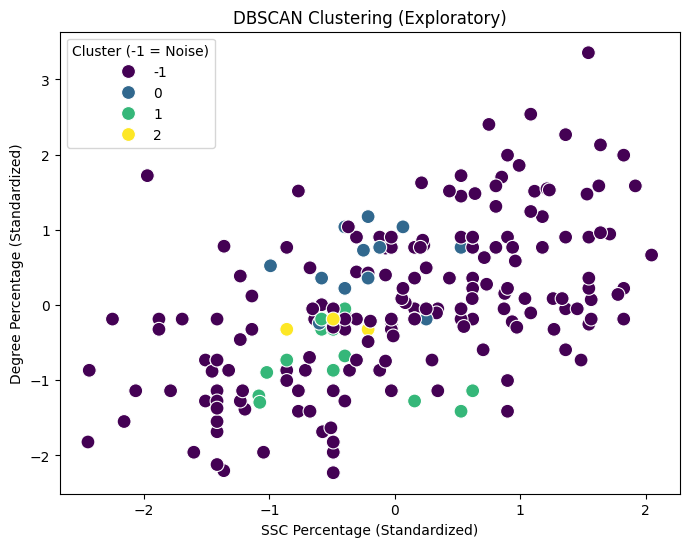

In [ ]:
dbscan_demo = DBSCAN(
    eps=1.5,
    min_samples=5
)

df["DBSCAN_Demo"] = dbscan_demo.fit_predict(X)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="ssc_p",
    y="degree_p",
    hue="DBSCAN_Demo",
    palette="viridis",
    s=100
)

plt.title("DBSCAN Clustering (Exploratory)")
plt.xlabel("SSC Percentage (Standardized)")
plt.ylabel("Degree Percentage (Standardized)")
plt.legend(title="Cluster (-1 = Noise)")
plt.show()

**Interpretation:**

- **What it shows:** the exploratory DBSCAN result, where purple points (-1) are noise and the coloured points belong to three small clusters (0, 1, 2).
- **Pattern:** the large majority of students are noise. The three small clusters are located in the central and lower-middle area of the plot and are not visually separated from the surrounding noise points (they may be closer in the other, unplotted features).
- **Conclusion:** DBSCAN does not find a meaningful structure for most students. This confirms that the dataset has no clear high-density groups separated by low-density gaps.

### 7.5 DBSCAN: Strengths and Limitations

| Strengths | Limitations |
|---|---|
| Does not require the number of clusters in advance | Very sensitive to `eps` and `min_samples` |
| Can find clusters of any shape | Struggles when density is uniform, as in this dataset |
| Identifies noise and outliers explicitly | Distances become less informative in higher dimensions |
| Useful as a check for dense group structure | No configuration met the selection criteria here |

## 8. Cluster Profiling

To understand what each cluster represents, the **average standardized academic scores** are calculated for each cluster. Because the values are standardized, a positive number means above the dataset average and a negative number means below average (in standard deviations). The DBSCAN profile is only shown if a final DBSCAN model was selected.

In [ ]:
# Compare average academic performance
academic_features = [
    "ssc_p",
    "hsc_p",
    "degree_p",
    "etest_p",
    "mba_p"
]

print("K-Means Cluster Characteristics:")

display(
    df.groupby("Cluster")[academic_features]
    .mean()
    .round(2)
)

print("Hierarchical Cluster Characteristics:")

display(
    df.groupby("HC_Cluster")[academic_features]
    .mean()
    .round(2)
)

if labels_dbscan is not None:
    print("DBSCAN Cluster Characteristics:")

    display(
        df.groupby("DBSCAN_Cluster")[academic_features]
        .mean()
        .round(2)
    )

K-Means Cluster Characteristics:


,ssc_p,hsc_p,degree_p,etest_p,mba_p
Cluster,,,,,
0,0.73,0.57,0.65,0.48,0.66
1,-0.61,-0.48,-0.54,-0.40,-0.56


Hierarchical Cluster Characteristics:


,ssc_p,hsc_p,degree_p,etest_p,mba_p
HC_Cluster,,,,,
0,0.50,0.43,0.42,0.10,0.45
1,-0.83,-0.72,-0.70,-0.17,-0.74


**Interpretation:**

**K-Means**

- **Cluster 0 (98 students):** above average in all five academic scores (+0.48 to +0.73). These are the **higher-performing students**.
- **Cluster 1 (117 students):** below average in all five scores (-0.40 to -0.61). These are the **lower-performing students**.

**Hierarchical (Ward)**

- **Cluster 0 (134 students):** above average (+0.42 to +0.50 for most scores).
- **Cluster 1 (81 students):** clearly below average (-0.70 to -0.83 for most scores).
- The employability test score (`etest_p`) differs only slightly between the Ward clusters (+0.10 vs. -0.17), while it differs more in K-Means (+0.48 vs. -0.40).

**DBSCAN:** no profile is shown because no final DBSCAN configuration was selected.

**Conclusion:** both K-Means and Ward clearly divide students into a **higher-performing** and a **lower-performing** academic group. K-Means produces a more balanced split, while Ward forms a smaller, more clearly low-performing group.

## 9. Algorithm Comparison

### 9.1 Summary Table from the Code

The final results of the three algorithms are collected into one table.

In [ ]:
comparison = {
    "Algorithm": [
        "K-Means",
        "DBSCAN",
        "Hierarchical (Ward)"
    ],

    "Number of Clusters": [
        len(set(labels_kmeans)),
        len(set(labels_dbscan) - {-1}) if labels_dbscan is not None else np.nan,
        len(set(labels_hc))
    ],

    "Silhouette Score": [
        silhouette_score(X, labels_kmeans),
        np.nan,
        silhouette_score(X, labels_hc)
    ],

    "Noise Points": [
        0,
        (labels_dbscan == -1).sum() if labels_dbscan is not None else np.nan,
        0
    ]
}

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Noise Points
0,K-Means,2.0,0.2015,0.0
1,DBSCAN,NaN,NaN,NaN
2,Hierarchical (Ward),2.0,0.1646,0.0


**Observation:** K-Means and Hierarchical Clustering both found 2 clusters with no noise points. DBSCAN shows `NaN` values because no configuration met the selection criteria in Section 7.3.

### 9.2 Detailed Comparison

| Criterion | K-Means | Hierarchical (Ward) | DBSCAN |
|---|---|---|---|
| Number of clusters | 2 | 2 | No final model (exploratory run: 3) |
| Cluster sizes | 98 / 117 | 134 / 81 | Exploratory run: 33 clustered points |
| Noise points | 0 (not applicable) | 0 (not applicable) | No final model (exploratory run: 182 of 215) |
| Silhouette Score (all points) | **0.2015** | 0.1646 | Not calculated for a final model |
| Silhouette Score (non-noise points only) | - | - | 0.2429 (exploratory run, 33 points only) |
| Cluster separation | Weak; clusters overlap in the middle | Weak; similar overlap | Most points labelled as noise |
| Key strengths | Highest valid Silhouette Score; balanced clusters; simple and fast | Deterministic; meaningful split with Ward linkage | Detects noise; no need to choose *k* |
| Key limitations | *k* must be chosen in advance; weak separation | Lower Silhouette Score; sensitive to linkage choice | Very sensitive to parameters; failed to find valid clusters |

### 9.3 Best-Performing Algorithm

Based on the available evidence, **K-Means (k = 2)** is the best-performing algorithm in this project:

- It has the **highest Silhouette Score (0.2015)** among the models evaluated on all 215 students.
- It produces **balanced and interpretable clusters** (higher-performing vs. lower-performing students).
- Its cluster profiles show clear differences in all five academic scores.

Hierarchical Clustering (Ward) finds a very similar structure and is a close alternative. DBSCAN was not suitable for this dataset because it could not form valid clusters without labelling most students as noise.

**Important caution:** the winning Silhouette Score is still low (about 0.20). K-Means is the best of the three methods tested, but the clusters it finds are **not strongly separated**.

## 10. Key Insights

1. **Two groups are the most natural division.** For K-Means, the Silhouette Score is highest at k = 2 and generally decreases as k increases.
2. **Academic performance drives the clusters.** Both K-Means and Ward separate students mainly into above-average and below-average academic groups.
3. **The clusters overlap.** All valid Silhouette Scores are around 0.16-0.20, and the scatter plots show mixing in the middle range of scores.
4. **The data has no clear density-based structure.** DBSCAN labels almost everyone as noise for small `eps` values and merges everyone into one cluster for larger values.
5. **Silhouette Score alone can be misleading.** Average and single linkage scored 0.2800 by isolating just one student, and DBSCAN scores ignored most of the data. Cluster sizes and noise counts must be checked together with the score.

## 11. Final Conclusion

### Project Summary

This project used unsupervised learning to group 215 students from the Campus Placement dataset. The data was checked for missing values and duplicates, the identifier and outcome columns (`sl_no`, `status`, `salary`) were removed, numerical features were standardized, and categorical features were one-hot encoded. K-Means, Hierarchical Clustering, and DBSCAN were then applied, tuned, and compared.

### Main Clustering Findings

- The students are best described by **two groups**: a **higher-performing** group and a **lower-performing** group across secondary, higher secondary, degree, employability test, and MBA scores.
- The boundary between the groups is **not sharp**; many students lie in between.
- No clear dense clusters exist in the data, so density-based clustering was not effective.

### Best-Performing Algorithm

**K-Means with k = 2** performed best, with the highest Silhouette Score on the full dataset (0.2015) and balanced, interpretable clusters (98 / 117). Hierarchical Clustering with Ward linkage gave a similar but slightly weaker result (0.1646).

### Strengths and Weaknesses of the Approaches

- **K-Means:** simple, fast, and gave the best result, but requires choosing *k* and assumes round clusters.
- **Hierarchical (Ward):** deterministic and gave a meaningful split, but results depend heavily on the linkage method.
- **DBSCAN:** good at detecting outliers without choosing *k*, but very sensitive to its parameters and unsuitable for this evenly spread data.

### Practical Applications

- Universities could use the two academic profiles to identify students who may benefit from **extra academic support** or placement training.
- Placement offices could design **different preparation programmes** for higher-performing and lower-performing groups.
- The clusters could be compared with the removed `status` column to explore how academic groups relate to placement outcomes.

### Future Improvements

- Use additional evaluation methods, such as the **Elbow Method**, **Davies-Bouldin Index**, or a **dendrogram**, to support the choice of the number of clusters.
- Scale the binary one-hot features or test clustering on **numerical features only** to study the effect of feature selection.
- Use a **k-distance plot** to choose `eps` for DBSCAN more systematically.
- Compare the final clusters with placement `status` to check whether the groups have practical meaning.